In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import cartopy.feature as cfeature

sys.path.insert(0, "../src")   # shared grid + map helpers live in src/grid.py
from grid import (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX, RES, lon_edges, lat_edges,
                  proj, style_map, cell_index)
from grid import nx as NX, ny as NY

In [2]:
DATA_DIR = Path("../data")      # data, tables, results (parquet, npz, csv, json)
FIG_DIR  = Path("../figures")   # all figures (png)

# Each notebook writes to its own subfolder; inputs come from earlier notebooks' folders
OUT_DIR = DATA_DIR / "06_reliability"
FIG_OUT = FIG_DIR / "06_reliability"
DIR_01  = DATA_DIR / "01_data_prep_roni_gdp"          # kuroshio_obs_clean, roni_phase
DIR_03  = DATA_DIR / "03_aggregation_and_means"       # agg_vel / agg_sst, weighting_diff
DIR_04  = DATA_DIR / "04_bootstrap"                   # bootstrap_velocity / bootstrap_sst
DIR_05  = DATA_DIR / "05_data_denial"                 # data_denial_1deg
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_OUT.mkdir(parents=True, exist_ok=True)

In [3]:
TARGET_CMPS = 10.0                                   # precision target (cm/s)
SST_TARGET_C = 0.5                                   # ±0.5 °C ≈ a tenth of the median seasonal range in a cell (Method 4.5)

VEL_LABELS = {0: "no data", 1: "too few drifters", 2: "enough drifters, not yet precise",
              3: "reliable", 4: "reliable, direction resolved"}
SST_LABELS = {0: "no data", 1: "missing a season", 2: "uncertainty too large",
              3: "seasonal bias too large", 4: "reliable"}
summary = {}

In [4]:
boot = pd.read_parquet(DIR_04 / "bootstrap_velocity_1deg.parquet")   # one row per grid cell, grid order
dd = np.load(DIR_05 / "data_denial_1deg.npz")

N_STAR = {"jet": int(dd["N_star_jet"]), "recirculation": int(dd["N_star_recirc"])}
JET_SPEED_CMPS = float(dd["jet_speed"]) * 100        # saved in m/s; bootstrap table is in cm/s

print(f"N*: {N_STAR}, jet threshold: {JET_SPEED_CMPS:.0f} cm/s")
print(f"{len(boot)} grid cells, {(boot['n_drifters'] > 0).sum()} with velocity data")

summary["N_star"] = N_STAR
summary["jet_threshold_cmps"] = round(JET_SPEED_CMPS, 2)

N*: {'jet': 83, 'recirculation': 26}, jet threshold: 34 cm/s
750 grid cells, 595 with velocity data


In [5]:
has_data = boot["n_drifters"] > 0

# Region and required drifters, from each cell's own mean speed
boot["region"] = np.where(boot["mean_vector_speed_cmps"] >= JET_SPEED_CMPS, "jet", "recirculation")
boot["N_star"] = boot["region"].map(N_STAR)

# The two conditions of the reliability criterion
enough  = boot["n_drifters"] >= boot["N_star"]                          # precision rule
precise = boot["bootstrap_vector_radius95_cmps"] <= TARGET_CMPS          # bootstrap uncertainty

boot["reliable"] = has_data & enough & precise
boot["direction_resolved"] = boot["reliable"] & (boot["snr"] > 1)
boot["drifters_needed"] = np.where(has_data, (boot["N_star"] - boot["n_drifters"]).clip(lower=0), np.nan)

# One category per cell for the map
boot["category"] = np.select(
    [~has_data, boot["direction_resolved"], boot["reliable"], enough & ~precise],
    [0, 4, 3, 2], default=1)
# 0 no data | 1 too few drifters | 2 enough drifters, not yet precise | 3 reliable | 4 reliable, direction resolved

In [6]:
d = boot[has_data]

region_table = pd.DataFrame({
    "cells with data":         d.groupby("region").size(),
    "reliable":                d.groupby("region")["reliable"].sum(),
    "share reliable":          d.groupby("region")["reliable"].mean().map("{:.0%}".format),
    "direction resolved":      d.groupby("region")["direction_resolved"].sum(),
    "median extra drifters (unreliable)": d[~d["reliable"]].groupby("region")["drifters_needed"].median(),
})
print(region_table, "\n")

print(d["category"].map(VEL_LABELS).value_counts())
print(f"\nAll cells with data: {d['reliable'].mean():.0%} reliable")

summary["velocity"] = {
    "cells_with_data": int(len(d)),
    "cells_by_region": {r: int(v) for r, v in d.groupby("region").size().items()},
    "reliable": int(d["reliable"].sum()),
    "reliable_by_region": {r: int(v) for r, v in d.groupby("region")["reliable"].sum().items()},
    "direction_resolved": int(d["direction_resolved"].sum()),
    "direction_resolved_by_region": {r: int(v) for r, v in d.groupby("region")["direction_resolved"].sum().items()},
    "share_reliable": round(float(d["reliable"].mean()), 4),
    "categories": {VEL_LABELS[k]: int((d["category"] == k).sum()) for k in range(1, 5)},
    "median_extra_drifters_unreliable": {r: float(v) for r, v in
                                         d[~d["reliable"]].groupby("region")["drifters_needed"].median().items()},
}

               cells with data  reliable share reliable  direction resolved  \
region                                                                        
jet                         54        17            31%                  17   
recirculation              541       293            54%                 167   

               median extra drifters (unreliable)  
region                                             
jet                                          25.0  
recirculation                                 8.0   

category
too few drifters                    249
reliable, direction resolved        184
reliable                            126
enough drifters, not yet precise     36
Name: count, dtype: int64

All cells with data: 52% reliable


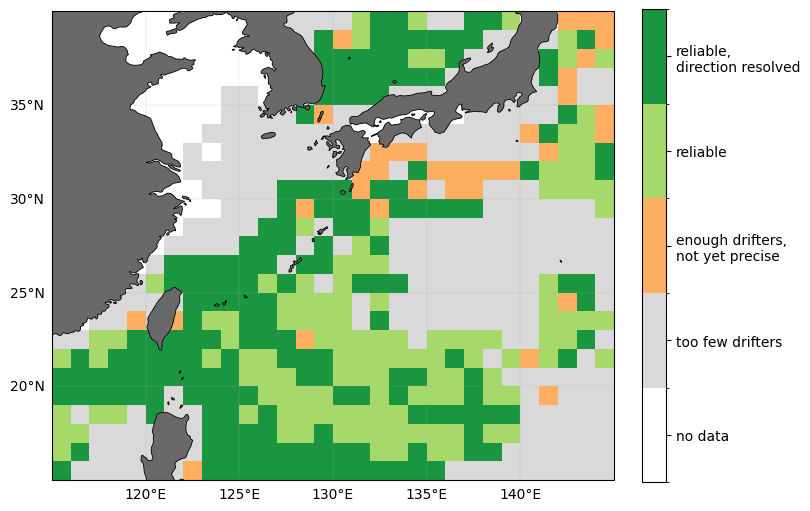

In [7]:
cmap = ListedColormap(["white", "#d9d9d9", "#fdae61", "#a6d96a", "#1a9641"])
norm = BoundaryNorm(np.arange(-0.5, 5.5), cmap.N)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": proj})
m = ax.pcolormesh(lon_edges, lat_edges, boot["category"].to_numpy().reshape(NY, NX),
                  cmap=cmap, norm=norm, transform=proj)
style_map(ax)
ax.add_feature(cfeature.LAND, facecolor="dimgrey", zorder=2.5)   # darker land: light grey is a category here

cb = fig.colorbar(m, ax=ax, ticks=range(5), shrink=0.8)
cb.ax.set_yticklabels(["no data", "too few drifters", "enough drifters,\nnot yet precise",
                       "reliable", "reliable,\ndirection resolved"])
fig.savefig(FIG_OUT / "reliability_map_velocity.png", dpi=300, bbox_inches="tight")
plt.show()

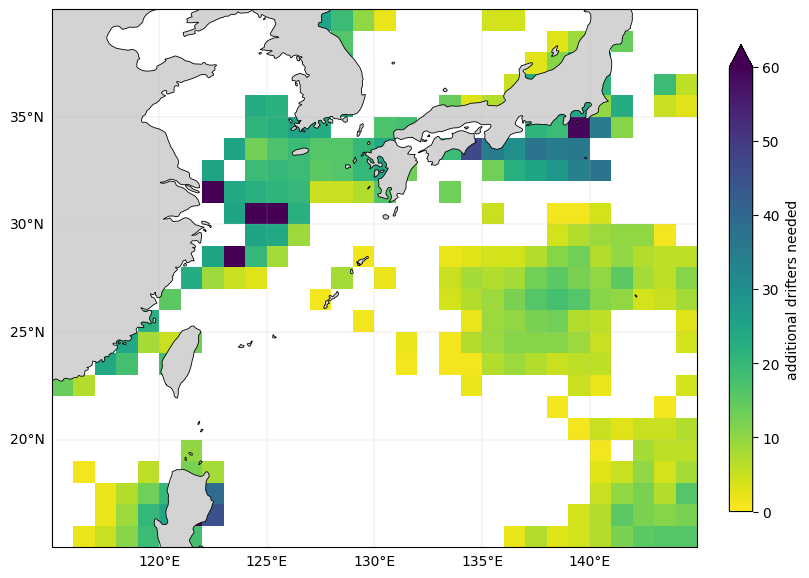

In [8]:
needed = boot["drifters_needed"].to_numpy(dtype=float, copy=True).reshape(NY, NX)
hide = (boot["reliable"] | (boot["category"] == 2)).to_numpy().reshape(NY, NX)
needed[hide] = np.nan          # show only cells limited by drifter count

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": proj})
m = ax.pcolormesh(lon_edges, lat_edges, needed, cmap="viridis_r", vmin=0, vmax=60, transform=proj)
style_map(ax)
fig.colorbar(m, ax=ax, shrink=0.8, extend="max", label="additional drifters needed")
fig.savefig(FIG_OUT / "drifters_needed_map.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
# Weighting sensitivity from the bootstrap table (04): per-drifter vs per-hour mean difference > U95
ci = boot["weighting_sensitive"].notna()                       # cells with a bootstrap interval
rel = boot["reliable"] & ci
ws = boot["weighting_sensitive"].astype("boolean")
summary["weighting_sensitive"] = {
    "all_ci_cells": {"n_cells": int(ci.sum()), "share": round(float(ws[ci].mean()), 4)},
    "reliable":     {"n_cells": int(rel.sum()), "share": round(float(ws[rel].mean()), 4)},
}
print(f"cells where the weighting difference exceeds U95: {ws[ci].mean():.0%} of {ci.sum()}")
print(f"reliable cells where it exceeds U95: {ws[rel].mean():.0%} of {rel.sum()}")

cells where the weighting difference exceeds U95: 38% of 577
reliable cells where it exceeds U95: 44% of 310


In [10]:
# --- Product table: velocity ---
boot["category_label"] = boot["category"].map(VEL_LABELS)
vel_cols = ["iy", "ix", "lon_center", "lat_center", "n_drifters", "n_hours",
            "mean_ve_cmps", "mean_vn_cmps", "mean_vector_speed_cmps",
            "ve_ci_low_cmps", "ve_ci_high_cmps", "ve_ci_halfwidth_cmps",
            "vn_ci_low_cmps", "vn_ci_high_cmps", "vn_ci_halfwidth_cmps",
            "bootstrap_vector_radius95_cmps", "snr", "region", "N_star", "reliable",
            "direction_resolved", "drifters_needed", "weighting_diff_cmps", "weighting_sensitive",
            "category", "category_label"]
boot[vel_cols].to_parquet(OUT_DIR / "product_velocity_1deg.parquet", index=False)
boot[vel_cols].to_csv(OUT_DIR / "product_velocity_1deg.csv", index=False)

In [11]:
sst = pd.read_parquet(DIR_04 / "bootstrap_sst_1deg.parquet")    # grid order, like boot
sst_has_data = sst["n_drifters"] > 0
sst["reliable"] = sst_has_data & (sst["sst_ci_halfwidth_c"] <= SST_TARGET_C)

print(f"SST cells with data: {sst_has_data.sum()}")
print(f"SST reliable (±{SST_TARGET_C} °C): {sst['reliable'].sum()} "
      f"({sst.loc[sst_has_data, 'reliable'].mean():.0%})")
print(f"Median SST CI half-width: {sst.loc[sst_has_data, 'sst_ci_halfwidth_c'].median():.2f} °C")

SST cells with data: 618
SST reliable (±0.5 °C): 163 (26%)
Median SST CI half-width: 0.78 °C


### Seasonal coverage and bias

In [12]:
obs = pd.read_parquet(DIR_01 / "kuroshio_obs_clean.parquet", columns=["id", "lon", "lat", "time", "sst"])
obs = obs[obs["sst"].notna()].copy()

# Grid cell and season of each observation
obs["iy"], obs["ix"] = cell_index(obs)
month = pd.to_datetime(obs["time"]).dt.month
obs["season"] = month.map({12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
                           6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"})

# Mean SST per cell and season (°C)
seas = (obs.groupby(["iy", "ix", "season"])["sst"].mean() - 273.15).unstack("season")
seas = seas.reindex(pd.MultiIndex.from_product([range(NY), range(NX)], names=["iy", "ix"]))
seasonal_range = seas.max(axis=1) - seas.min(axis=1)
four = (seas.notna().sum(axis=1) == 4).to_numpy()
summary["median_seasonal_range_c"] = {"all_cells": round(float(seasonal_range.median()), 3),
                                      "cells_with_4_seasons": round(float(seasonal_range[four].median()), 3)}
print(f"median seasonal range per cell: {seasonal_range.median():.1f} °C (all cells), "
      f"{seasonal_range[four].median():.1f} °C (cells with all 4 seasons)")

sst["n_seasons"] = seas.notna().sum(axis=1).to_numpy()
sst["sst_balanced_c"] = seas.mean(axis=1).where(sst["n_seasons"].to_numpy() == 4).to_numpy()
sst["seasonal_bias_c"] = sst["mean_sst_c"] - sst["sst_balanced_c"]

# Updated SST reliability: all four seasons, precise, and not seasonally biased
sst["reliable"] = (sst_has_data & (sst["n_seasons"] == 4)
                   & (sst["sst_ci_halfwidth_c"] <= SST_TARGET_C)
                   & (sst["seasonal_bias_c"].abs() <= SST_TARGET_C))

d = sst[sst_has_data]
print(f"cells with all 4 seasons: {(d['n_seasons'] == 4).mean():.0%}")
print(f"median |seasonal bias|: {d['seasonal_bias_c'].abs().median():.2f} °C")
print(f"cells with |bias| > {SST_TARGET_C} °C: {(d['seasonal_bias_c'].abs() > SST_TARGET_C).sum()}")
print(f"SST reliable (updated): {d['reliable'].sum()} ({d['reliable'].mean():.0%})")

median seasonal range per cell: 5.5 °C (all cells), 5.6 °C (cells with all 4 seasons)
cells with all 4 seasons: 90%
median |seasonal bias|: 0.32 °C
cells with |bias| > 0.5 °C: 178
SST reliable (updated): 147 (24%)


### SST Reliability Map

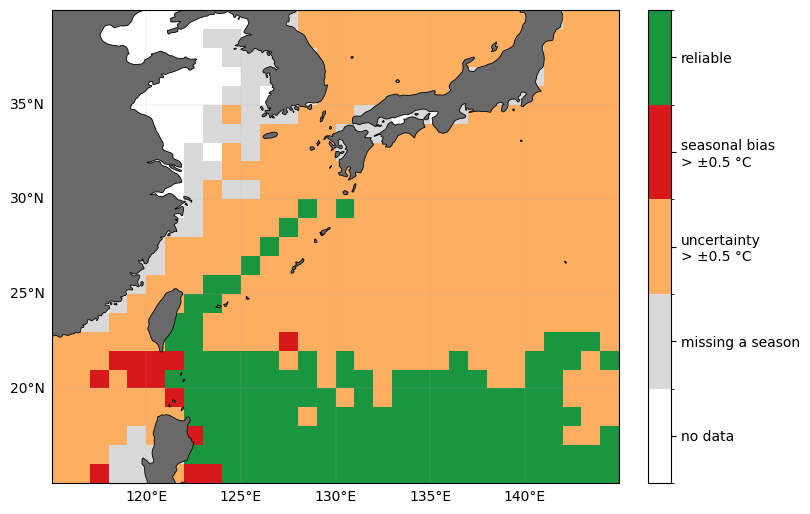

sst_category
uncertainty too large      398
reliable                   147
missing a season            60
seasonal bias too large     13
Name: count, dtype: int64 

missing_season: 60
halfwidth_gt_target: 435
abs_bias_gt_target: 178
half-width and bias both fail: 165


In [13]:
# One category per cell, checked in order: the first failing condition is shown
missing_season = sst["n_seasons"] < 4
imprecise      = sst["sst_ci_halfwidth_c"] > SST_TARGET_C
biased         = sst["seasonal_bias_c"].abs() > SST_TARGET_C

sst["sst_category"] = np.select(
    [~sst_has_data, missing_season, imprecise, biased],
    [0, 1, 2, 3], default=4)
# 0 no data | 1 missing a season | 2 uncertainty > ±0.5 °C | 3 seasonal bias > ±0.5 °C | 4 reliable

cmap_s = ListedColormap(["white", "#d9d9d9", "#fdae61", "#d7191c", "#1a9641"])
norm_s = BoundaryNorm(np.arange(-0.5, 5.5), cmap_s.N)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": proj})
m = ax.pcolormesh(lon_edges, lat_edges, sst["sst_category"].to_numpy().reshape(NY, NX),
                  cmap=cmap_s, norm=norm_s, transform=proj)
style_map(ax)
ax.add_feature(cfeature.LAND, facecolor="dimgrey", zorder=2.5)   # darker land: light grey is a category here

cb = fig.colorbar(m, ax=ax, ticks=range(5), shrink=0.8)
cb.ax.set_yticklabels(["no data", "missing a season",
                       f"uncertainty\n> ±{SST_TARGET_C} °C", f"seasonal bias\n> ±{SST_TARGET_C} °C",
                       "reliable"])
fig.savefig(FIG_OUT / "reliability_map_sst.png", dpi=300, bbox_inches="tight")
plt.show()

# Counts for the Results text: map category (first failing condition) ...
d = sst[sst_has_data]
print(d["sst_category"].map(SST_LABELS).value_counts(), "\n")

# ... and each condition on its own (a cell can fail several)
fail = {"missing_season": missing_season[sst_has_data],
        "halfwidth_gt_target": imprecise[sst_has_data],
        "abs_bias_gt_target": biased[sst_has_data]}
overlap = int((fail["halfwidth_gt_target"] & fail["abs_bias_gt_target"]).sum())
for k, v in fail.items():
    print(f"{k}: {int(v.sum())}")
print(f"half-width and bias both fail: {overlap}")

summary["sst"] = {
    "target_c": SST_TARGET_C,
    "cells_with_data": int(len(d)),
    "cells_with_4_seasons": int((d["n_seasons"] == 4).sum()),
    "halfwidth_le_target": int((d["sst_ci_halfwidth_c"] <= SST_TARGET_C).sum()),
    "abs_bias_gt_target": int((d["seasonal_bias_c"].abs() > SST_TARGET_C).sum()),
    "median_abs_bias_c": round(float(d["seasonal_bias_c"].abs().median()), 3),
    "reliable": int(d["reliable"].sum()),
    "share_reliable": round(float(d["reliable"].mean()), 4),
    "map_categories": {SST_LABELS[k]: int((d["sst_category"] == k).sum()) for k in range(1, 5)},
    "fails_each_condition": {k: int(v.sum()) for k, v in fail.items()},
    "halfwidth_and_bias_both_fail": overlap,
}

In [14]:
# --- Product table: SST ---
sst["sst_category_label"] = sst["sst_category"].map(SST_LABELS)
sst_cols = ["iy", "ix", "lon_center", "lat_center", "n_drifters", "n_hours", "mean_sst_c",
            "sst_ci_low_c", "sst_ci_high_c", "sst_ci_halfwidth_c", "n_seasons", "sst_balanced_c",
            "seasonal_bias_c", "reliable", "sst_category", "sst_category_label"]
sst[sst_cols].to_parquet(OUT_DIR / "product_sst_1deg.parquet", index=False)
sst[sst_cols].to_csv(OUT_DIR / "product_sst_1deg.csv", index=False)

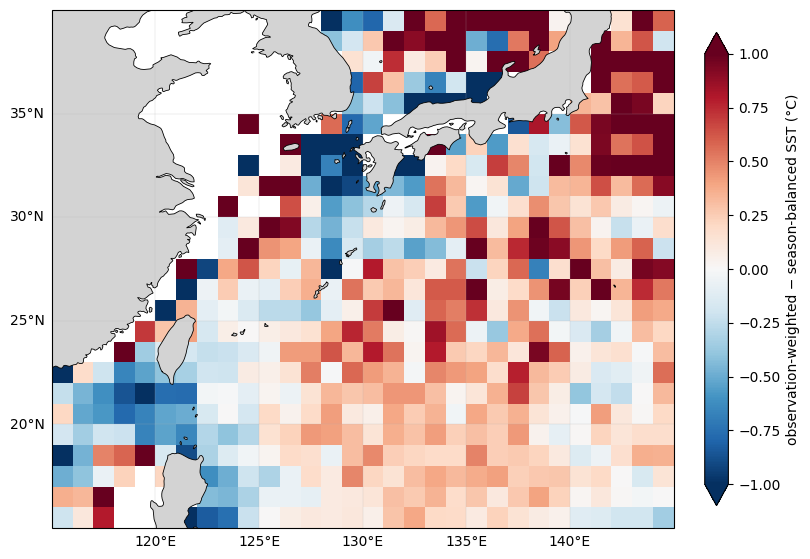

In [15]:
bias = sst["seasonal_bias_c"].to_numpy(dtype=float, copy=True).reshape(NY, NX)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": proj})
m = ax.pcolormesh(lon_edges, lat_edges, bias, cmap="RdBu_r", vmin=-1, vmax=1, transform=proj)
style_map(ax)
fig.colorbar(m, ax=ax, shrink=0.8, extend="both",
             label="observation-weighted − season-balanced SST (°C)")
fig.savefig(FIG_OUT / "sst_seasonal_bias_map.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
(OUT_DIR / "06_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "N_star": {
    "jet": 83,
    "recirculation": 26
  },
  "jet_threshold_cmps": 34.0,
  "velocity": {
    "cells_with_data": 595,
    "cells_by_region": {
      "jet": 54,
      "recirculation": 541
    },
    "reliable": 310,
    "reliable_by_region": {
      "jet": 17,
      "recirculation": 293
    },
    "direction_resolved": 184,
    "direction_resolved_by_region": {
      "jet": 17,
      "recirculation": 167
    },
    "share_reliable": 0.521,
    "categories": {
      "too few drifters": 249,
      "enough drifters, not yet precise": 36,
      "reliable": 126,
      "reliable, direction resolved": 184
    },
    "median_extra_drifters_unreliable": {
      "jet": 25.0,
      "recirculation": 8.0
    }
  },
  "weighting_sensitive": {
    "all_ci_cells": {
      "n_cells": 577,
      "share": 0.383
    },
    "reliable": {
      "n_cells": 310,
      "share": 0.4355
    }
  },
  "median_seasonal_range_c": {
    "all_cells": 5.519,
    "cells_with_4_seasons": 5.624
  },
  "sst"